In [1]:
# Step 1: basic config
from ultralytics import YOLO

# we will test multiple random seeds
seeds = [42, 2024, 77]   # 你可以改成自己喜欢的 3 个数字

# choose base model
base_model_path = "yolov8n.pt"   # 这周我们用 YOLOv8n 做多次实验


In [2]:
# Step 2: train YOLOv8n with different seeds

for s in seeds:
    print(f"===== Training with seed = {s} =====")
    
    model = YOLO(base_model_path)
    
    model.train(
        data="thermal.yaml",      # 你之前写好的数据配置
        epochs=20,                # 和之前保持一致，时间不够可以适当减小
        imgsz=640,
        batch=16,
        seed=s,                   # ★ 本次最关键：设置随机种子
        name=f"thermal_yolov8n_seed{s}"  # 每个 seed 一套独立的 run 目录
    )


===== Training with seed = 42 =====
New https://pypi.org/project/ultralytics/8.3.234 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.229 🚀 Python-3.8.10 torch-2.4.1+cu118 CUDA:0 (NVIDIA RTX A5000, 24248MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=thermal.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=thermal_y

In [3]:
# Step 3: read csv and extract metrics for each seed

import pandas as pd
import os

records = []   # 用来收集每次实验的结果

for s in seeds:
    run_dir = os.path.join("runs", "detect", f"thermal_yolov8n_seed{s}")
    csv_path = os.path.join(run_dir, "results.csv")
    
    if not os.path.exists(csv_path):
        print(f"[WARN] results.csv not found for seed {s}: {csv_path}")
        continue
    
    # read csv
    df = pd.read_csv(csv_path)
    
    # take the last row (final epoch)
    last = df.iloc[-1]
    
    # extract metrics
    precision = float(last["metrics/precision(B)"])
    recall    = float(last["metrics/recall(B)"])
    map5095   = float(last["metrics/mAP50-95(B)"])
    
    # score = 0.1 * P + 0.1 * R + 0.8 * mAP50-95
    score = precision * 0.1 + recall * 0.1 + map5095 * 0.8
    
    # save this result
    records.append({
        "Model"     : f"YOLOv8n_seed{s}",
        "Seed"      : s,
        "Precision" : precision,
        "Recall"    : recall,
        "mAP50-95"  : map5095,
        "Score"     : score
    })

# make summary table
summary_df = pd.DataFrame(records)
summary_df


,Model,Seed,Precision,Recall,mAP50-95,Score
0,YOLOv8n_seed42,42,0.98852,0.99300,0.92924,0.941544
1,YOLOv8n_seed2024,2024,0.98388,0.99651,0.92745,0.939999
2,YOLOv8n_seed77,77,0.98785,0.99542,0.93007,0.942383


In [12]:
%matplotlib inline


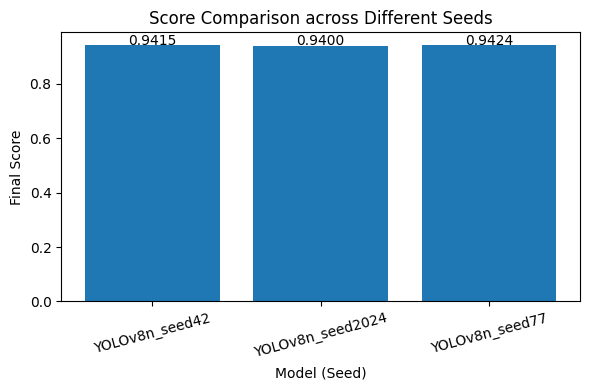

In [13]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
bars = plt.bar(summary_df["Model"], summary_df["Score"])

plt.ylabel("Final Score")
plt.xlabel("Model (Seed)")
plt.title("Score Comparison across Different Seeds")
plt.xticks(rotation=15)

# 在柱子上显示数值
for bar in bars:
    y = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2, 
        y + 0.002, 
        f"{y:.4f}", 
        ha='center'
    )

plt.tight_layout()
plt.show()
